<a href="https://colab.research.google.com/github/Awimya-Rn/PCVK26_13_Ilham/blob/main/Week_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. PRAKTIKUM MORFOLOGI

## 1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

## 3

In [ ]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

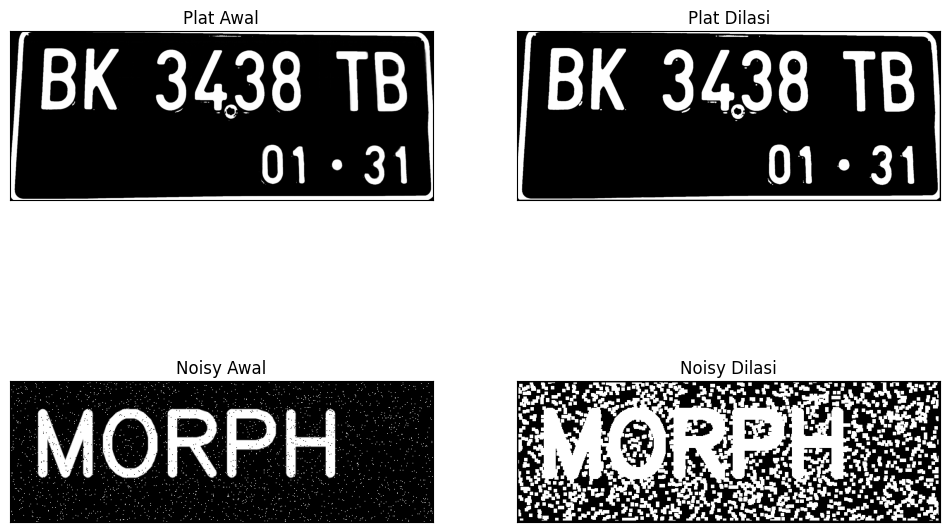

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 125, 200, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD_plat = dilasi_citra(thresh1, w)
imgD_noisy = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgD_plat, cmap='gray'), plt.title('Plat Dilasi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgD_noisy, cmap='gray'), plt.title('Noisy Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 4

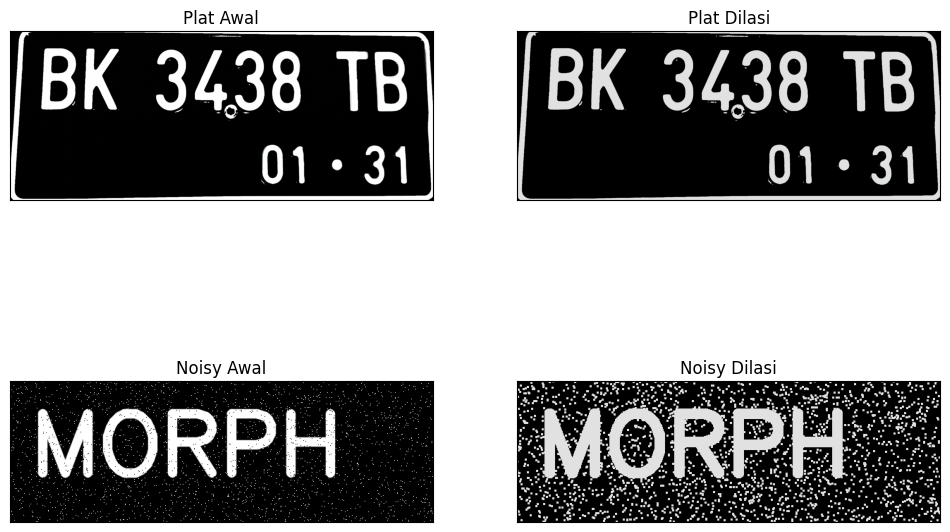

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg')
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png')

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint16)
dilasi_plat = cv2.dilate(thresh1, kernel, iterations=1)
dilasi_noisy = cv2.dilate(thresh2, kernel, iterations=1)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(dilasi_plat), plt.title('Plat Dilasi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(dilasi_noisy), plt.title('Noisy Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 5

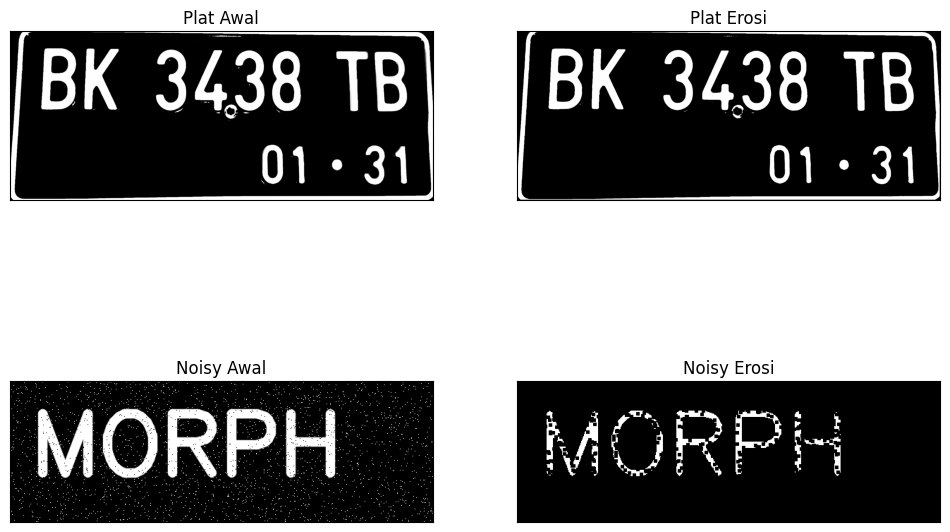

In [ ]:
def erosi_citra(F,k):
  m,n= F.shape
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 175, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE_plat = erosi_citra(thresh1, k)
imgE_noisy = erosi_citra(thresh2, k)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgE_plat, cmap='gray'), plt.title('Plat Erosi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgE_noisy, cmap='gray'), plt.title('Noisy Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 6

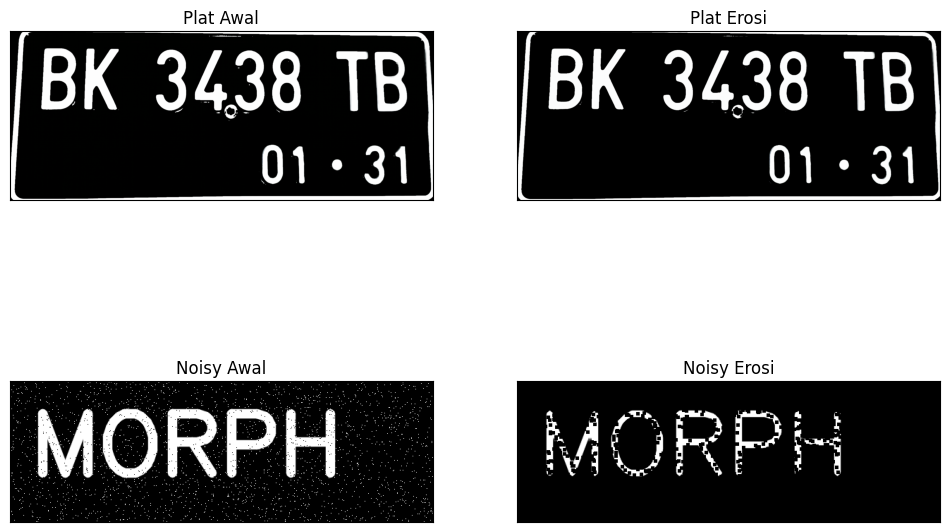

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg')
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png')

kernel = np.ones((5, 5), np.uint8)
erosion_plat = cv2.erode(img_plat, kernel, iterations=1)
erosion_noisy = cv2.erode(img_noisy, kernel, iterations=1)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(erosion_plat), plt.title('Plat Erosi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(erosion_noisy), plt.title('Noisy Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 7

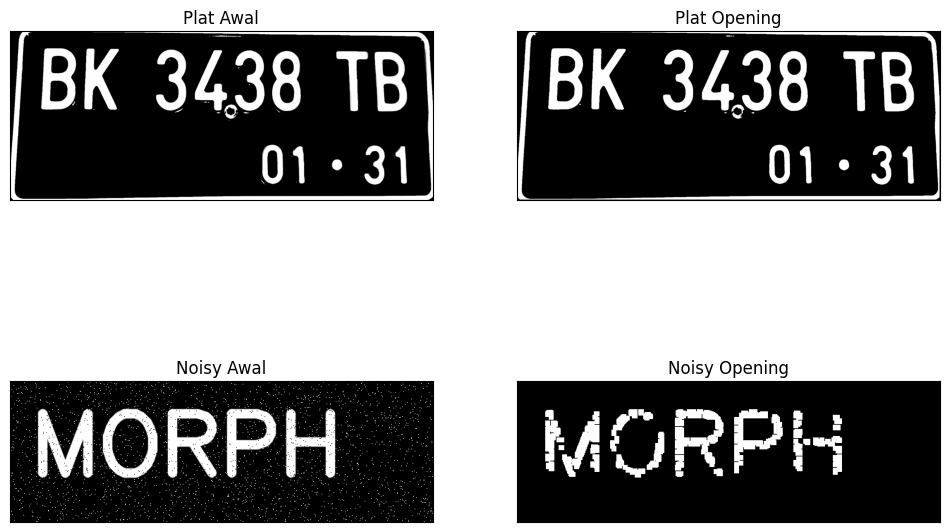

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

reto1, thresho1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
reto2, thresho2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

k = 7
imgO_plat = dilasi_citra(erosi_citra(thresho1, k), k)
imgO_noisy = dilasi_citra(erosi_citra(thresho2, k), k)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgO_plat, cmap='gray'), plt.title('Plat Opening'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgO_noisy, cmap='gray'), plt.title('Noisy Opening'), plt.xticks([]), plt.yticks([])
plt.show()

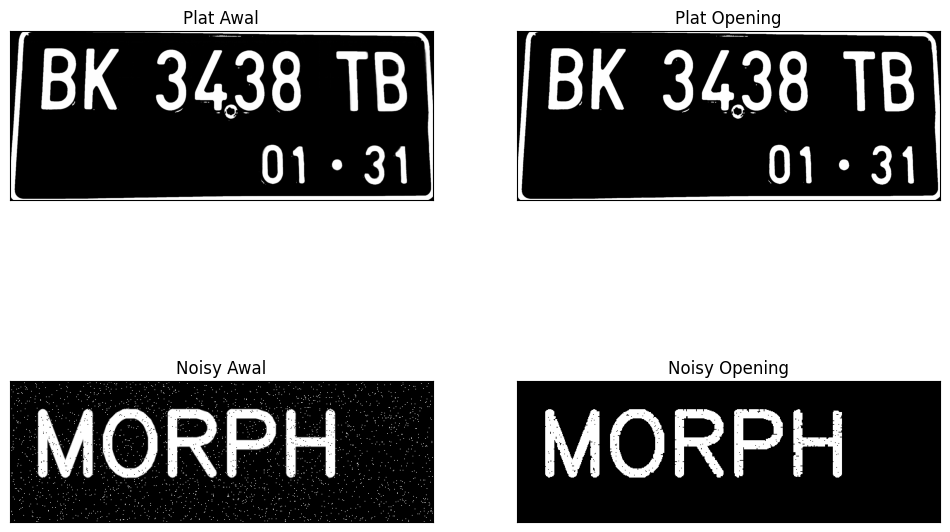

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
openn_plat = cv2.morphologyEx(thresh1, cv2.MORPH_OPEN, kernel)
openn_noisy = cv2.morphologyEx(thresh2, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(openn_plat, cmap='gray'), plt.title('Plat Opening'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(openn_noisy, cmap='gray'), plt.title('Noisy Opening'), plt.xticks([]), plt.yticks([])
plt.show()

## 8

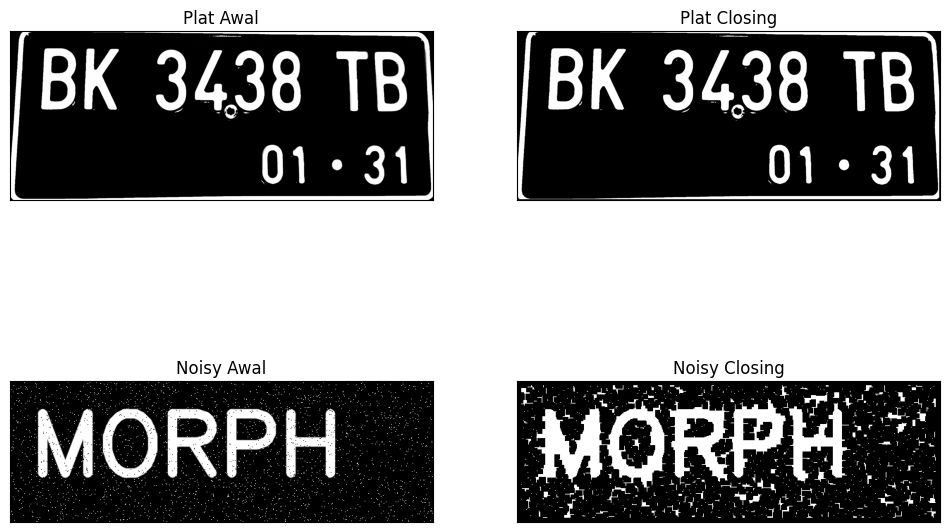

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

retc1, threshc1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
retc2, threshc2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

k = 7
imgC_plat = erosi_citra(dilasi_citra(threshc1, k), k)
imgC_noisy = erosi_citra(dilasi_citra(threshc2, k), k)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgC_plat, cmap='gray'), plt.title('Plat Closing'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgC_noisy, cmap='gray'), plt.title('Noisy Closing'), plt.xticks([]), plt.yticks([])
plt.show()

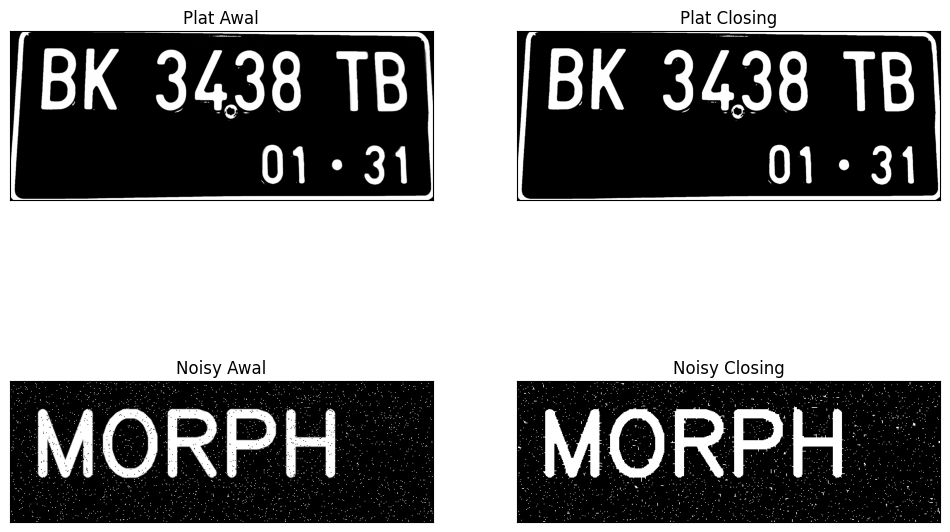

In [ ]:
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
closs_plat = cv2.morphologyEx(thresh1, cv2.MORPH_CLOSE, kernel)
closs_noisy = cv2.morphologyEx(thresh2, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(closs_plat, cmap='gray'), plt.title('Plat Closing'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(closs_noisy, cmap='gray'), plt.title('Noisy Closing'), plt.xticks([]), plt.yticks([])
plt.show()

## 9

SED = Cross 3


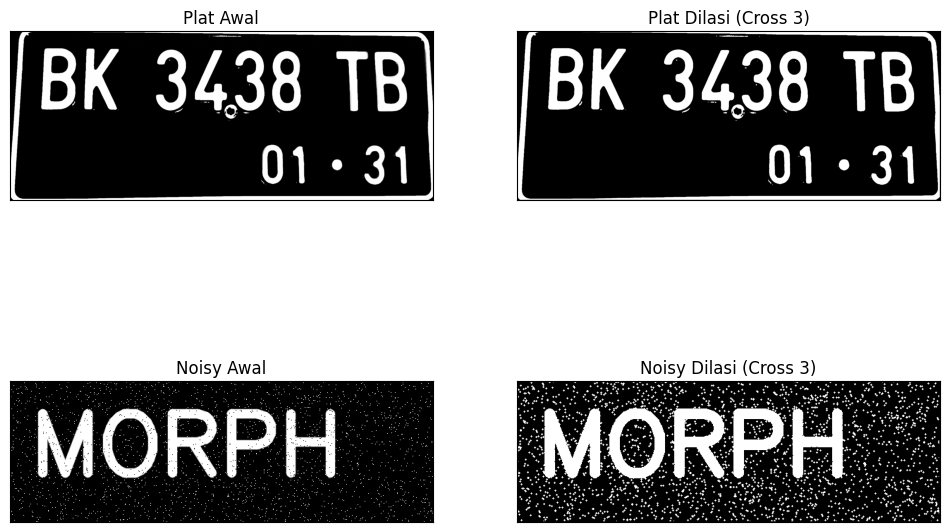

In [ ]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
  [1, 1, 1],
  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 3')
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

w = 3
imgD_plat = dilasi_citra(thresh1, w)
imgD_noisy = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgD_plat, cmap='gray'), plt.title('Plat Dilasi (Cross 3)'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgD_noisy, cmap='gray'), plt.title('Noisy Dilasi (Cross 3)'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 5


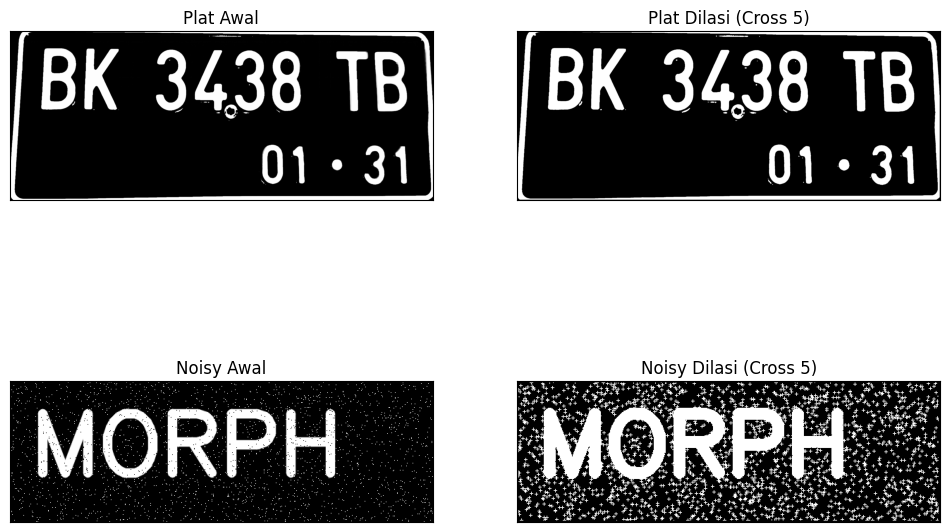

In [ ]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
  [0, 0, 1, 0, 0],
  [1, 1, 1, 1, 1],
  [0, 0, 1, 0, 0],
  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 5')
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

w = 5
imgD_plat = dilasi_citra(thresh1, w)
imgD_noisy = dilasi_citra(thresh2, w)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(imgD_plat, cmap='gray'), plt.title('Plat Dilasi (Cross 5)'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(imgD_noisy, cmap='gray'), plt.title('Noisy Dilasi (Cross 5)'), plt.xticks([]), plt.yticks([])
plt.show()

## 10

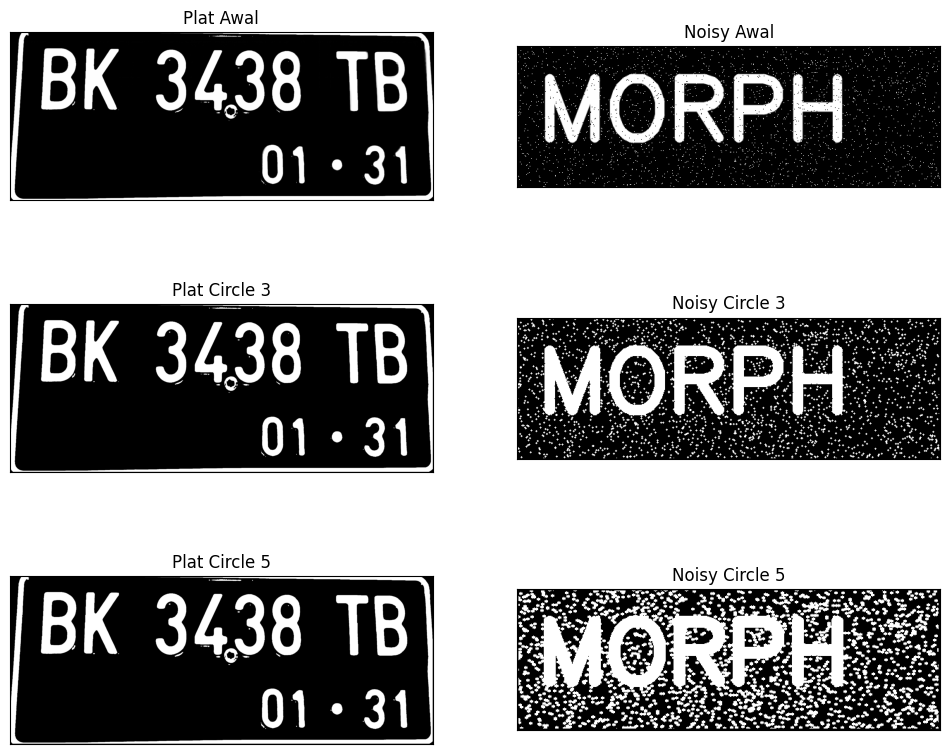

In [ ]:
def dilasi_citra(F,w):
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Circle 3
imgD_plat3 = dilasi_citra(thresh1, 3)
imgD_noisy3 = dilasi_citra(thresh2, 3)

# Circle 5
imgD_plat5 = dilasi_citra(thresh1, 5)
imgD_noisy5 = dilasi_citra(thresh2, 5)

plt.figure(figsize=(12, 10))
plt.subplot(321), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(322), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(323), plt.imshow(imgD_plat3, cmap='gray'), plt.title('Plat Circle 3'), plt.xticks([]), plt.yticks([])
plt.subplot(324), plt.imshow(imgD_noisy3, cmap='gray'), plt.title('Noisy Circle 3'), plt.xticks([]), plt.yticks([])
plt.subplot(325), plt.imshow(imgD_plat5, cmap='gray'), plt.title('Plat Circle 5'), plt.xticks([]), plt.yticks([])
plt.subplot(326), plt.imshow(imgD_noisy5, cmap='gray'), plt.title('Noisy Circle 5'), plt.xticks([]), plt.yticks([])
plt.show()

## 11

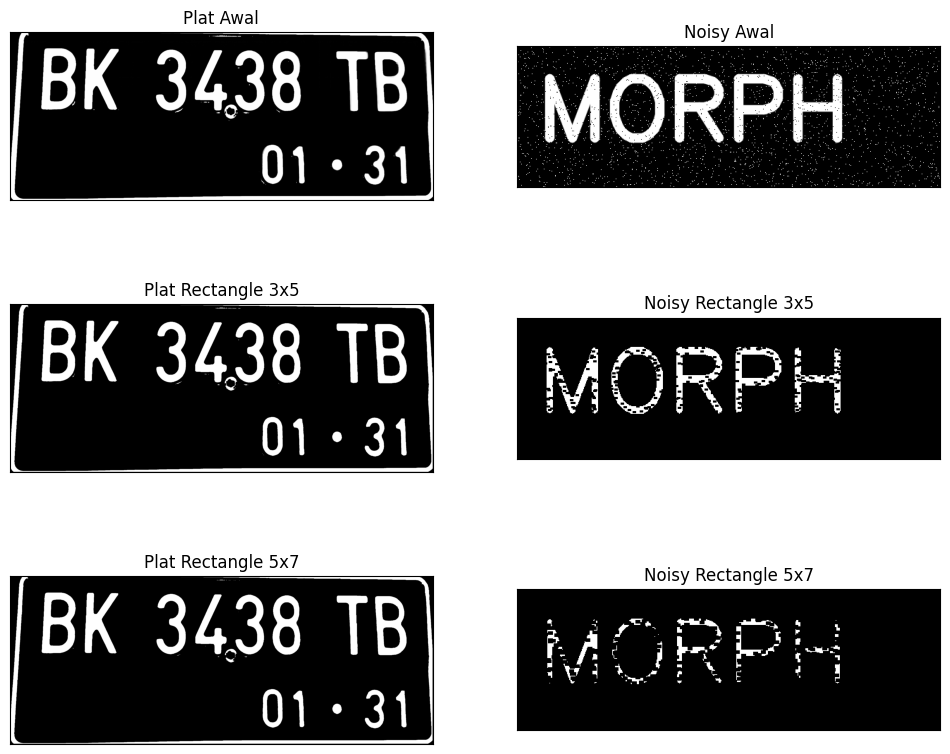

In [ ]:
def erosi_citra(F,p,l):
  m,n= F.shape
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l))
  constant1= (l-1)//2
  constant2= (p-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Rectangle 3x5
imgE_plat35 = erosi_citra(thresh1, 5, 3)
imgE_noisy35 = erosi_citra(thresh2, 5, 3)

# Rectangle 5x7
imgE_plat57 = erosi_citra(thresh1, 7, 5)
imgE_noisy57 = erosi_citra(thresh2, 7, 5)

plt.figure(figsize=(12, 10))
plt.subplot(321), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(322), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(323), plt.imshow(imgE_plat35, cmap='gray'), plt.title('Plat Rectangle 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(324), plt.imshow(imgE_noisy35, cmap='gray'), plt.title('Noisy Rectangle 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(325), plt.imshow(imgE_plat57, cmap='gray'), plt.title('Plat Rectangle 5x7'), plt.xticks([]), plt.yticks([])
plt.subplot(326), plt.imshow(imgE_noisy57, cmap='gray'), plt.title('Noisy Rectangle 5x7'), plt.xticks([]), plt.yticks([])
plt.show()

## 12

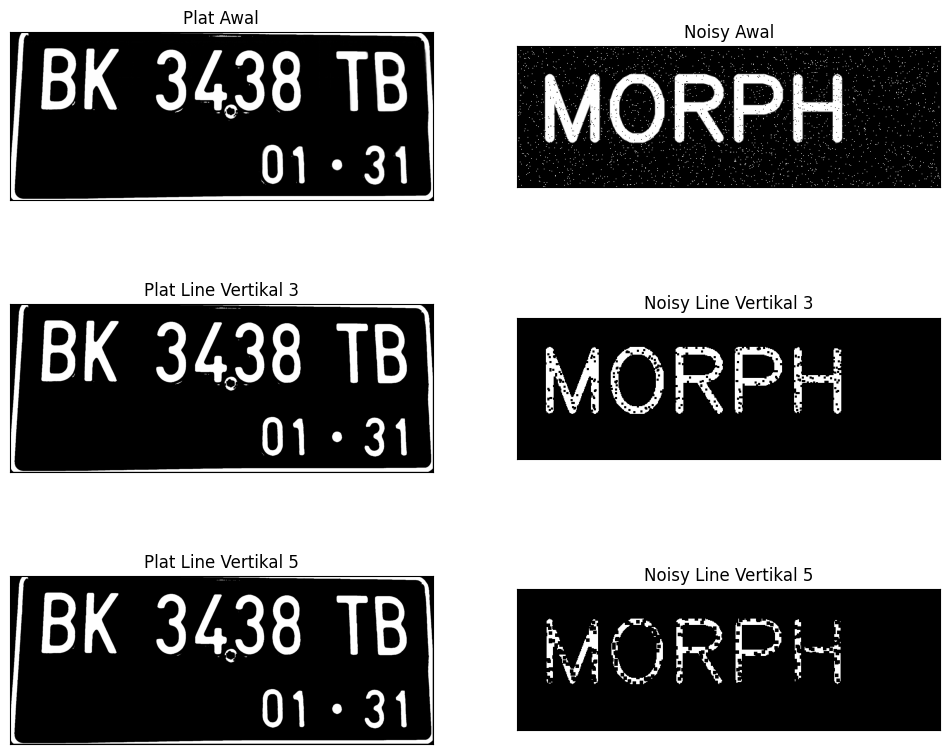

In [ ]:
def erosi_citra(F,k):
  m,n= F.shape
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k))
  constant= (k-1)//2
  imgE= np.zeros((m,n), dtype=np.uint8)
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)
  return imgE

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/plat.jpeg', 0)
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

ret1, thresh1 = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)

# Line Vertikal 3
imgE_plat3 = erosi_citra(thresh1, 3)
imgE_noisy3 = erosi_citra(thresh2, 3)

# Line Vertikal 5
imgE_plat5 = erosi_citra(thresh1, 5)
imgE_noisy5 = erosi_citra(thresh2, 5)

plt.figure(figsize=(12, 10))
plt.subplot(321), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(322), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(323), plt.imshow(imgE_plat3, cmap='gray'), plt.title('Plat Line Vertikal 3'), plt.xticks([]), plt.yticks([])
plt.subplot(324), plt.imshow(imgE_noisy3, cmap='gray'), plt.title('Noisy Line Vertikal 3'), plt.xticks([]), plt.yticks([])
plt.subplot(325), plt.imshow(imgE_plat5, cmap='gray'), plt.title('Plat Line Vertikal 5'), plt.xticks([]), plt.yticks([])
plt.subplot(326), plt.imshow(imgE_noisy5, cmap='gray'), plt.title('Noisy Line Vertikal 5'), plt.xticks([]), plt.yticks([])
plt.show()

## 13

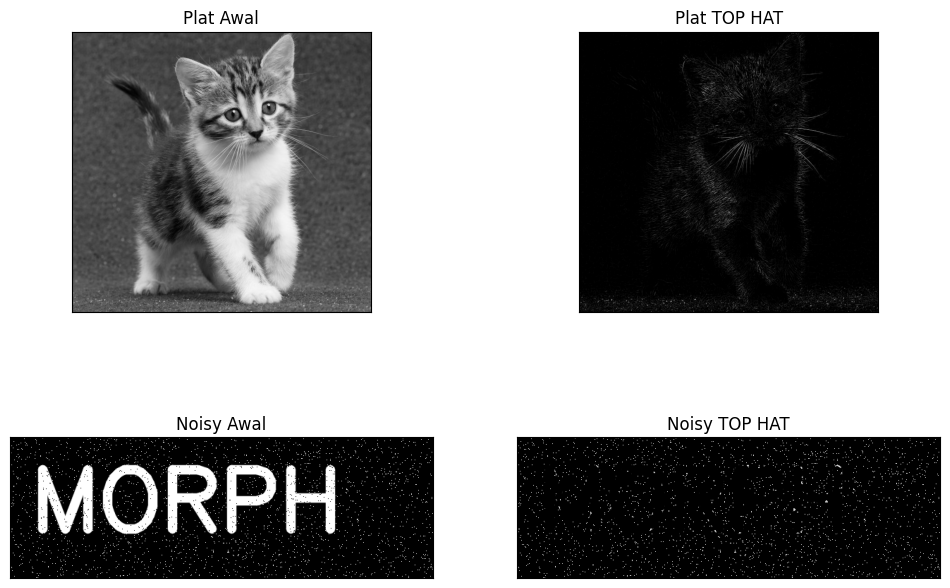

In [ ]:
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png')
img_noisy = cv2.cvtColor(img_noisy, cv2.COLOR_BGR2GRAY)

tophat_plat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
tophat_noisy = cv2.morphologyEx(img_noisy, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(tophat_plat, cmap='gray'), plt.title('Plat TOP HAT'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(tophat_noisy, cmap='gray'), plt.title('Noisy TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

## 14

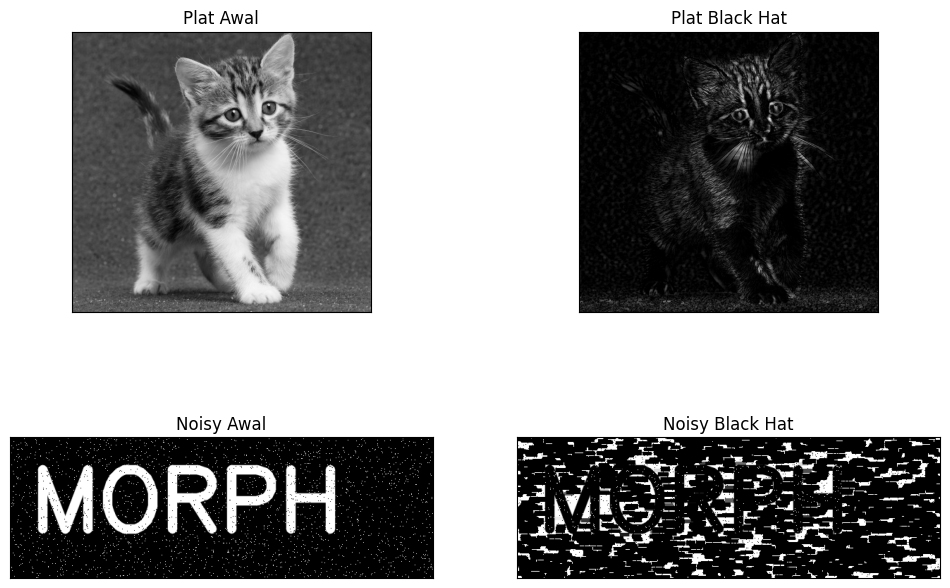

In [ ]:
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png')
img_noisy = cv2.cvtColor(img_noisy, cv2.COLOR_BGR2GRAY)

blackhat_plat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
blackhat_noisy = cv2.morphologyEx(img_noisy, cv2.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(blackhat_plat, cmap='gray'), plt.title('Plat Black Hat'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(blackhat_noisy, cmap='gray'), plt.title('Noisy Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

## 15

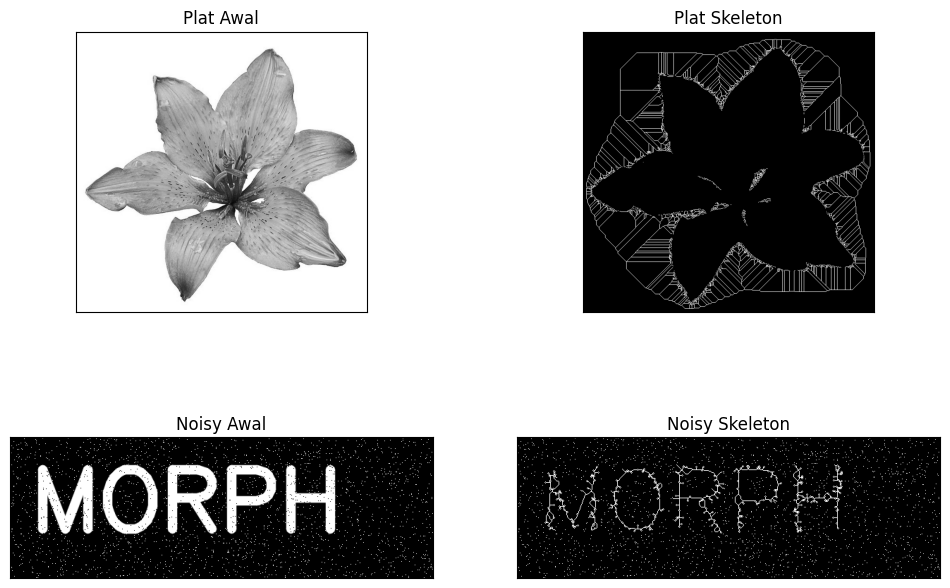

In [ ]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/lily.jpg', 0)
img_noisy = cv.imread('/content/drive/MyDrive/PCVK/Images/244107020139/noisy_text.png', 0)

binary_plat = img > filters.threshold_triangle(img)
binary_noisy = img_noisy > filters.threshold_triangle(img_noisy)

binary_plat_cp = binary_plat.copy()
binary_plat_cp[binary_plat_cp == True] = 1
binary_plat_cp[binary_plat_cp == False] = 0

binary_noisy_cp = binary_noisy.copy()
binary_noisy_cp[binary_noisy_cp == True] = 1
binary_noisy_cp[binary_noisy_cp == False] = 0

skeleton_plat = skeletonize(binary_plat_cp)
skeleton_noisy = skeletonize(binary_noisy_cp)

plt.figure(figsize=(12, 8))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(skeleton_plat, cmap='gray'), plt.title('Plat Skeleton'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_noisy, cmap='gray'), plt.title('Noisy Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(skeleton_noisy, cmap='gray'), plt.title('Noisy Skeleton'), plt.xticks([]), plt.yticks([])
plt.show()

## 16

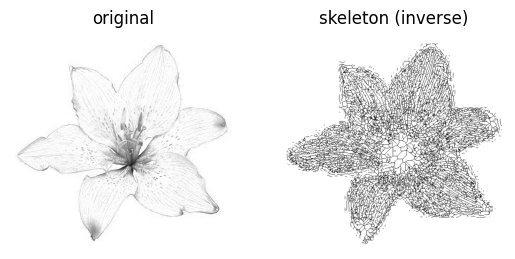

In [ ]:
from skimage import io, color
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK/Images/244107020139/lily.jpg')[...,0]

binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

## 17

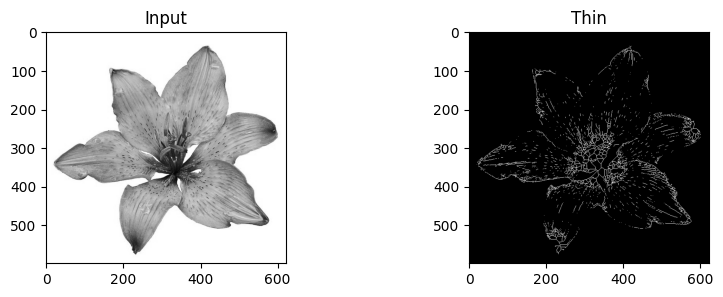

In [ ]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/244107020139/lily.jpg')))

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()